In [96]:
# -----------------------------------------------
# -----------------------------------------------
# LIBRERIE

# Base
import math
import os
from math import sqrt

# Base 2.0
import numpy as np
import pandas as pd

# Grafici
import matplotlib.pyplot as plt
import plotly.express as px
import seaborn as sns
from mpl_toolkits.mplot3d import Axes3D

# SciPy
from scipy import stats
from scipy.cluster.hierarchy import (
    dendrogram,
    fcluster,
    linkage,
)
from scipy.spatial.distance import pdist, squareform

# Scikit-learn
from sklearn.cluster import (
    AgglomerativeClustering,
    BisectingKMeans,
    cluster_optics_dbscan,
    DBSCAN,
    KMeans,
    OPTICS,
)
from sklearn.decomposition import PCA
from sklearn.ensemble import RandomForestRegressor
from sklearn.experimental import enable_iterative_imputer
from sklearn.impute import IterativeImputer
from sklearn.linear_model import (
    LinearRegression,
    Ridge,
    RidgeCV,
    Lasso,
    LassoCV,
)
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    mean_absolute_error,
    mean_squared_error,
    roc_auc_score,
    r2_score,
    RocCurveDisplay,
    silhouette_score,
    silhouette_samples,
)
from sklearn.model_selection import (
    cross_val_score,
    train_test_split,
)
from sklearn.naive_bayes import (
    CategoricalNB,
    GaussianNB,
)
from sklearn.neighbors import (
    KNeighborsClassifier,
    NearestNeighbors,
    KNeighborsRegressor,
)
from sklearn.preprocessing import (
    MinMaxScaler,
    StandardScaler,
)
from sklearn.tree import (
    DecisionTreeClassifier,
    DecisionTreeRegressor,
    plot_tree,
)

# Pattern Mining
from fim import (
    fpgrowth,
    apriori,
)

# Xmeans

from pyclustering.cluster import xmeans

In [97]:
# CARICAMENTO DATAFRAME

# Base e Cleaned
df = pd.read_csv("DM1_game_dataset.csv")
df_cleaned = pd.read_csv("df_cleaned.csv")

# Train & Test
train_set = pd.read_csv("train_set.csv")
test_set = pd.read_csv("test_set.csv")

# Imputed
train_imputed = pd.read_csv("train_imputed.csv")
test_imputed = pd.read_csv("test_imputed.csv")

# Transformed
train_transformed = pd.read_csv("train_transformed.csv")
test_transformed = pd.read_csv("test_transformed.csv")

In [98]:
# Identificazione Colonne

# Qualitative
colonne_quali = df_cleaned.select_dtypes(include=["object"]).columns
colonne_quali = colonne_quali + ["BGGId"]

# Ranking
colonne_rank = [
    "Rank:strategygames", "Rank:abstracts", "Rank:familygames",
    "Rank:thematic", "Rank:cgs", "Rank:wargames",
    "Rank:partygames", "Rank:childrensgames"
]
# Categorie
colonne_cat = ["Cat:Thematic", "Cat:Strategy", "Cat:War", "Cat:Family",
               "Cat:CGS", "Cat:Abstract", "Cat:Party", "Cat:Childrens"]

# Binarie
colonne_binarie = ["Kickstarted", "IsReimplementation", "RatingBinaria"]

# Quantitative
colonne_quanti = df_cleaned.select_dtypes(
    include=["int64", "float64"]).columns

# Numeriche
colonne_numeriche = (
    colonne_quanti.tolist()
)
colonne_numeriche = list(dict.fromkeys(colonne_numeriche))

In [99]:
# Misc

# Stile Grafici
sns.set(style="whitegrid")
plt.rcParams['figure.figsize'] = (8, 4)

# Scalers
standard_scaler = StandardScaler()
minmax_scaler = MinMaxScaler()

# Numerosità
n_train = len(train_set["Rating"])
n_test = len(test_set["Rating"])

In [100]:
# -----------------------------------------------
# -----------------------------------------------
# PATTERN MINING

In [101]:
# Dataset Creation

# RATING -> CAT, MediaPlaytime, ComAgeRec, GameWeight

# Discretizzazione
# in questo modo perchè df_cleaned ha ancora valori da imputare
df_pattern_prov = pd.concat([train_imputed, test_imputed],
                            axis=0, ignore_index=True)

df_pattern = df_pattern_prov.join(df[colonne_cat])
df_pattern = df_pattern[(df_pattern[colonne_cat] != 0).any(axis=1)]

# Category
df_pattern["Category"] = "0"


def estraicategorie(riga):
    # Prendiamo il nome della colonna (senza il prefisso 'Cat:') se il valore è > 0
    attive = [col.replace("Cat:", "") for col in colonne_cat if riga[col] != 0]
    # Uniamo i nomi con un underscore
    return "/".join(attive)


df_pattern["Category"] = df_pattern.apply(estraicategorie, axis=1)


# Weight
df_pattern["Weight_Bin"] = df_pattern["GameWeight"].round()


# Playtime
condizione1 = [
    (df_pattern['MediaPlaytime'] <= 30),
    (df_pattern['MediaPlaytime'] > 30) & (
        df_pattern['MediaPlaytime'] <= 60),
    (df_pattern['MediaPlaytime'] > 60) & (
        df_pattern['MediaPlaytime'] <= 120),
    (df_pattern['MediaPlaytime'] > 120)
]
tempo = [
    '0-30',
    '30-60',
    '60-120',
    '120+']
df_pattern['Playtime_Bin'] = np.select(condizione1, tempo, default=None)


# Recommended Age
condizione2 = [
    (df_pattern['ComAgeRec'] <= 6),
    (df_pattern['ComAgeRec'] > 6) & (
        df_pattern['ComAgeRec'] <= 14),
    (df_pattern['ComAgeRec'] > 14) & (
        df_pattern['ComAgeRec'] < 18),
    (df_pattern['ComAgeRec'] >= 18)
]
eta_rac = [
    '0-6',
    '7-13',
    '14-17',
    "18+"
]
df_pattern['RecommendedAge_Bin'] = np.select(
    condizione2, eta_rac, default=None)


df_pattern["Category"] = df_pattern["Category"].astype(str) + "_CAT"
df_pattern["Weight_Bin"] = df_pattern["Weight_Bin"].astype(str) + "_Weight"
df_pattern["RecommendedAge_Bin"] = df_pattern["RecommendedAge_Bin"].astype(
    str) + "_Age"
df_pattern["Playtime_Bin"] = df_pattern["Playtime_Bin"].astype(
    str) + "_Playtime"
df_pattern["Rating"] = df_pattern["Rating"] + "_Rating"


df_pattern = df_pattern.select_dtypes(include=["object"])
df_pattern = df_pattern.drop(["Family", "Rec_Year", "Period"], axis=1)
pm = df_pattern.values.tolist()

In [102]:
# -----------------------------------------------
# -----------------------------------------------
# APRIORI

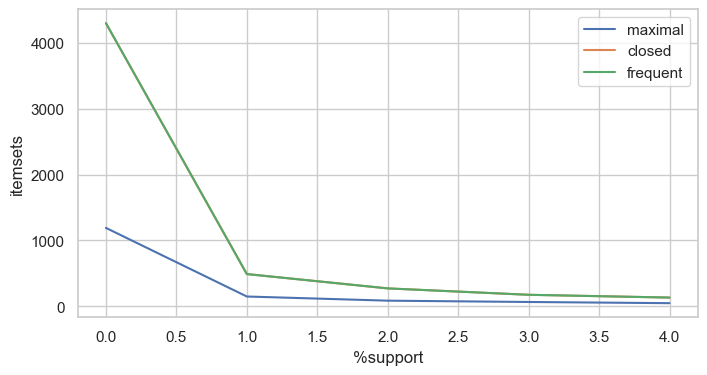

In [103]:
# Support Plot

len_max_it = []
len_cl_it = []
len_fr_it = []
max_supp = 5
zmin_plot = 2
for i in range(0, max_supp):
    max_itemsets = apriori(pm, target="m", supp=i, zmin=zmin_plot)
    cl_itemsets = apriori(pm, target="c", supp=i, zmin=zmin_plot)
    fr_itemsets = apriori(pm, target="s", supp=i, zmin=zmin_plot)
    len_max_it.append(len(max_itemsets))
    len_cl_it.append(len(cl_itemsets))
    len_fr_it.append(len(cl_itemsets))


plt.plot(np.arange(0, max_supp), len_max_it, label="maximal")
plt.plot(np.arange(0, max_supp), len_cl_it, label="closed")
plt.plot(np.arange(0, max_supp), len_fr_it, label="frequent")
plt.legend()
plt.xlabel("%support")
plt.ylabel("itemsets")
plt.show()

# si evince che closed e frequent sono pressochè identici; con 0 di SUPP in teoria sono profondamente diversi (circa 1000 pattern), ma già da 0.1 hanno una differenza di semplici decine,
# ad 1 (prob anche prima) sono identici

In [ ]:
# Iperparametri
supp = 2.5
zmin = 2
conf = 64

In [105]:
# Frequent

itemsets = apriori(pm, target="s", supp=supp, zmin=zmin, report="S")
pd.DataFrame(itemsets, columns=["frequent_itemset", "support"])

,frequent_itemset,support
0,"(Strategy/Family_CAT, 7-13_Age)",2.549521
1,"(Party_CAT, 7-13_Age)",3.156099
2,"(4.0_Weight, 14-17_Age)",2.521088
3,"(4.0_Weight, 120+_Playtime)",3.156099
4,"(4.0_Weight, High_Rating)",3.648943
...,...,...
220,"(2.0_Weight, 7-13_Age)",39.787698
221,"(0-30_Playtime, Medium_Rating)",20.102360
222,"(0-30_Playtime, Medium_Rating, 7-13_Age)",15.789973
223,"(0-30_Playtime, 7-13_Age)",32.072789


In [106]:
# Closed

itemsets = apriori(pm, target="c", supp=supp, zmin=zmin, report="S")
pd.DataFrame(itemsets, columns=["closed_itemset", "support"])

,closed_itemset,support
0,"(Strategy/Family_CAT, 7-13_Age)",2.549521
1,"(Party_CAT, 7-13_Age)",3.156099
2,"(4.0_Weight, 14-17_Age)",2.521088
3,"(4.0_Weight, 120+_Playtime)",3.156099
4,"(4.0_Weight, High_Rating)",3.648943
...,...,...
220,"(2.0_Weight, 7-13_Age)",39.787698
221,"(0-30_Playtime, Medium_Rating)",20.102360
222,"(0-30_Playtime, Medium_Rating, 7-13_Age)",15.789973
223,"(0-30_Playtime, 7-13_Age)",32.072789


In [107]:
# Maximal

itemsets = apriori(pm, target="m", supp=supp, zmin=zmin, report="S")
pd.DataFrame(itemsets, columns=["maximal_itemset", "support"])

,maximal_itemset,support
0,"(Strategy/Family_CAT, 7-13_Age)",2.549521
1,"(Party_CAT, 7-13_Age)",3.156099
2,"(4.0_Weight, 14-17_Age)",2.521088
3,"(4.0_Weight, 120+_Playtime)",3.156099
4,"(4.0_Weight, High_Rating)",3.648943
...,...,...
71,"(War_CAT, Low_Rating, 0-30_Playtime, 7-13_Age)",3.582599
72,"(War_CAT, 2.0_Weight, 0-30_Playtime, Medium_Ra...",2.587432
73,"(1.0_Weight, Low_Rating, 0-30_Playtime, 7-13_Age)",7.060942
74,"(1.0_Weight, 0-30_Playtime, Medium_Rating, 7-1...",6.397498


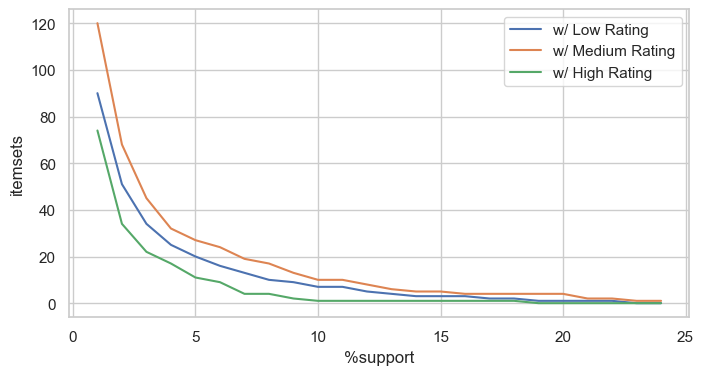

In [108]:
# Support vs Rating

filter_1 = []
filter_2 = []
filter_3 = []
max_supp = 25
for i in range(1, max_supp):
    max_itemsets = apriori(pm, target="s", supp=i, zmin=zmin)
    filter_1.append(
        len([item for item in max_itemsets if "Low_Rating" in item[0]]))
    filter_2.append(
        len([item for item in max_itemsets if "Medium_Rating" in item[0]]))
    filter_3.append(
        len([item for item in max_itemsets if "High_Rating" in item[0]]))

plt.plot(np.arange(1, max_supp), filter_1, label="w/ Low Rating")
plt.plot(np.arange(1, max_supp), filter_2, label="w/ Medium Rating")
plt.plot(np.arange(1, max_supp), filter_3, label="w/ High Rating")
plt.legend()
plt.xticks()
plt.xlabel("%support")
plt.ylabel("itemsets")
plt.show()

In [109]:
# Rules
rules = apriori(pm, target="r", supp=supp,
                zmin=zmin, conf=conf, report="aScl")
rules_df = pd.DataFrame(
    rules,
    columns=[
        "consequent",
        "antecedent",
        "abs_support",
        "%_support",
        "confidence",
        "lift",
    ],
)
rules_df.sort_values(by="lift", axis=0, ascending=False)

,consequent,antecedent,abs_support,%_support,confidence,lift
2,120+_Playtime,"(4.0_Weight, 14-17_Age)",199,1.886077,0.748120,7.149835
27,1.0_Weight,"(0-6_Age, Low_Rating, 0-30_Playtime)",607,5.753009,0.915535,3.032909
28,1.0_Weight,"(0-6_Age, Low_Rating)",678,6.425931,0.887435,2.939819
5,High_Rating,"(4.0_Weight, 7-13_Age)",209,1.980855,0.683007,2.938989
32,1.0_Weight,"(0-6_Age, 0-30_Playtime)",974,9.231352,0.881448,2.919987
...,...,...,...,...,...,...
126,7-13_Age,"(War_CAT, 1.0_Weight, Medium_Rating)",225,2.132499,0.673653,0.870829
16,7-13_Age,"(Abstract_CAT, 1.0_Weight)",178,1.687044,0.664179,0.858583
140,7-13_Age,"(1.0_Weight, 0-30_Playtime, Medium_Rating)",675,6.397498,0.659824,0.852953
122,7-13_Age,"(War_CAT, 1.0_Weight, 0-30_Playtime, Medium_Ra...",181,1.715477,0.646429,0.835637


In [110]:
# Association Rules for High Rating
rules_df[rules_df["consequent"] == "High_Rating"]

,consequent,antecedent,abs_support,%_support,confidence,lift
3,High_Rating,"(4.0_Weight, 14-17_Age)",171,1.620699,0.642857,2.766226
4,High_Rating,"(4.0_Weight, 120+_Playtime)",219,2.075633,0.657658,2.829913
5,High_Rating,"(4.0_Weight, 7-13_Age)",209,1.980855,0.683007,2.938989
6,High_Rating,"(4.0_Weight,)",385,3.648943,0.664940,2.861247


In [111]:
len_r = []

epsilon = (1/1000000000)
min_sup = 1
max_sup = 5
step_sup = 0.2
support_range = np.arange(min_sup, max_sup, step_sup)

min_conf = 50
max_conf = 70
step_conf = 1
conf_range = np.arange(min_conf, max_conf, step_conf)

for i in support_range:  # support
    len_r_wrt_i = []
    for j in conf_range:  # confidence
        rules = apriori(pm, target="r", supp=i,
                        zmin=zmin, conf=j, report="aScl")
        # study your characteristics/properties here
        len_r_wrt_i.append(len(rules))

    len_r.append(len_r_wrt_i)
len_r = np.array(len_r)

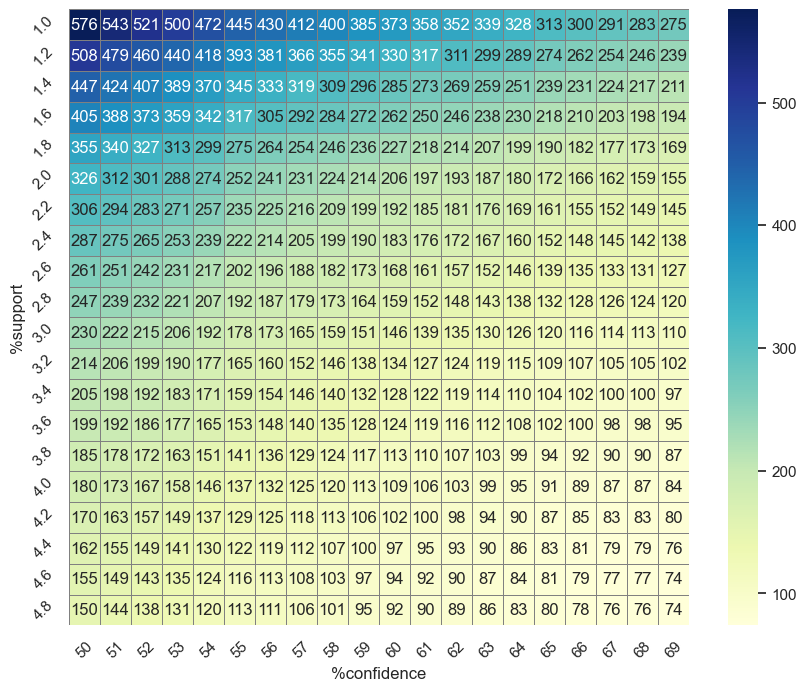

In [112]:
# Heatmap
# È buona norma definire la dimensione della figura prima
plt.figure(figsize=(10, 8))

sns.heatmap(len_r,
            cmap="YlGnBu",
            fmt='g',
            xticklabels=np.round(conf_range, 2),
            yticklabels=np.round(support_range, 2),
            linewidths=0.5,    # Aggiunge la griglia (spessore linea)
            linecolor='gray',  # Colore della griglia
            annot=True)        # Mostra i valori/percentuali dentro le celle

plt.xlabel("%confidence")
plt.ylabel("%support")
plt.xticks(rotation=45)
plt.yticks(rotation=45)
plt.show()